In [1]:
import pandas as pd

df = pd.read_parquet("../data/yellow_tripdata_2025-01.parquet")
df["duration"] = (df.tpep_dropoff_datetime - df.tpep_pickup_datetime).dt.total_seconds() / 60
df.shape, df["duration"].describe()

((3475226, 21),
 count    3.475226e+06
 mean     1.501812e+01
 std      3.871358e+01
 min     -5.147232e+04
 25%      7.283333e+00
 50%      1.170000e+01
 75%      1.833333e+01
 max      5.626317e+03
 Name: duration, dtype: float64)

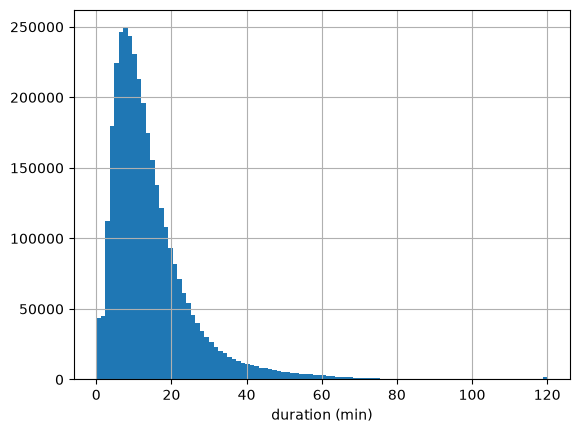

(3339105, 21)

In [2]:
#  look at the duration distribution and apply the filter
import matplotlib.pyplot as plt

df["duration"].clip(0, 120).hist(bins=100)
plt.xlabel("duration (min)")
plt.show()

df = df[(df.duration >= 1) & (df.duration <= 60)]
df = df[(df.trip_distance > 0) & (df.trip_distance <= 100)]
df.shape

In [3]:
# check missing values and odd rows
display(df.isna().sum())
display((df.trip_distance == 0).sum(), df.trip_distance.describe())

VendorID                      0
tpep_pickup_datetime          0
tpep_dropoff_datetime         0
passenger_count          486450
trip_distance                 0
RatecodeID               486450
store_and_fwd_flag       486450
PULocationID                  0
DOLocationID                  0
payment_type                  0
fare_amount                   0
extra                         0
mta_tax                       0
tip_amount                    0
tolls_amount                  0
improvement_surcharge         0
total_amount                  0
congestion_surcharge     486450
Airport_fee              486450
cbd_congestion_fee            0
duration                      0
dtype: int64

np.int64(0)

count    3.339105e+06
mean     3.061011e+00
std      3.873979e+00
min      1.000000e-02
25%      1.010000e+00
50%      1.700000e+00
75%      3.100000e+00
max      9.488000e+01
Name: trip_distance, dtype: float64

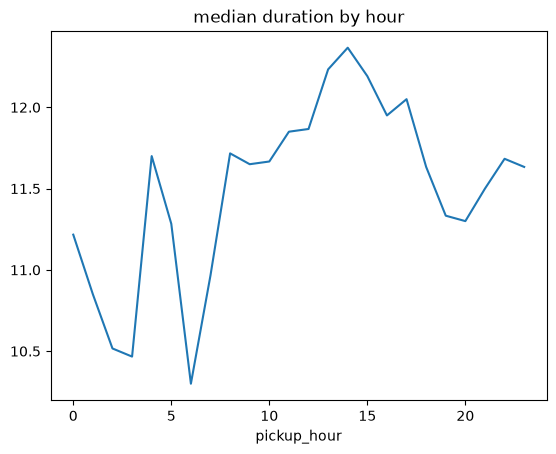

,duration,trip_distance,passenger_count
duration,1.000000,0.800175,0.037709
trip_distance,0.800175,1.000000,0.042013
passenger_count,0.037709,0.042013,1.000000


In [4]:
# add time features and check how they relate to duration
df["pickup_hour"] = df.tpep_pickup_datetime.dt.hour
df["pickup_dow"] = df.tpep_pickup_datetime.dt.day_of_week

df.groupby("pickup_hour").duration.median().plot(title="median duration by hour")
plt.show()
df[["duration", "trip_distance", "passenger_count"]].corr()

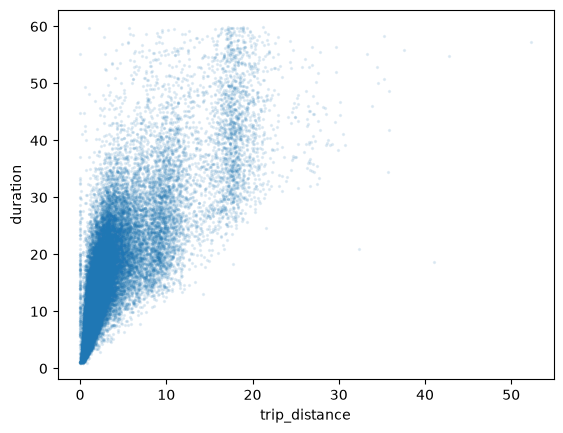

In [5]:
# take a sample so the plot doesn't have to draw 3.4M points
sample = df.sample(50_000, random_state=42)
sample.plot.scatter(x="trip_distance", y="duration", alpha=0.1, s=2)
plt.show()